# BBO capstone — Weeks 1–12: data, progress and query selection

**Reconstructed teaching/reference notebook**, not the original historical notebook. Uses the recorded initial observations and the 12 submitted queries per function. Run from the repository root.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.optimisation import read_function_data, propose_query
print("Repository root:", ROOT)


Matplotlib is building the font cache; this may take a moment.


Repository root: /Users/eceerkan/Imperial-ML-AI-Capstone-Project


## Dataset overview
The table below shows dataset sizes and the strongest observed value for each function. The unknown global optimum is not provided.

In [2]:
summary = pd.read_json(ROOT / "data/processed/summary.json")
display(summary)
weekly = pd.read_csv(ROOT / "data/processed/query_history.csv")
assert len(weekly) == 12 * 8
assert weekly.groupby("function").size().eq(12).all()


,function,dimensions,initial_count,weekly_count,total_count,initial_best,best_observed,best_source
0,1,2,10,12,22,7.710875e-16,2.708042e-13,week 6
1,2,2,10,12,22,6.112052e-01,6.547668e-01,week 11
2,3,3,15,12,27,-3.483531e-02,-3.224842e-02,week 11
3,4,4,30,12,42,-4.025542e+00,6.329212e-01,week 12
4,5,4,20,12,32,1.088860e+03,8.282121e+03,week 8
5,6,5,20,12,32,-7.142649e-01,-1.122331e-01,week 10
6,7,6,30,12,42,1.364968e+00,2.435566e+00,week 8
7,8,8,40,12,52,9.598482e+00,9.990837e+00,week 11


## Best-so-far curves
Function outputs have very different scales, so they are plotted separately.

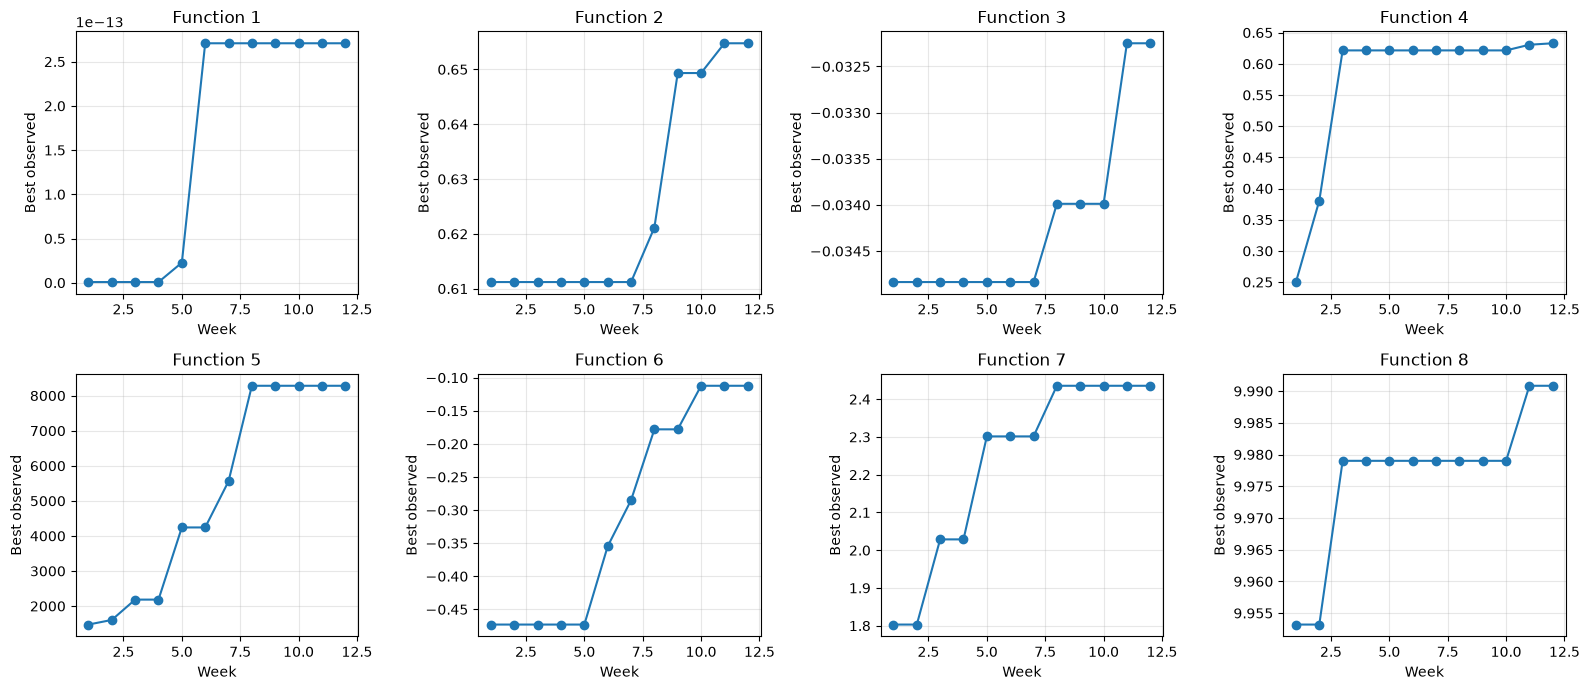

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for f, ax in zip(range(1, 9), axes.flat):
    X, y = read_function_data(ROOT, f)
    starter_n = int(summary.loc[summary.function.eq(f), "initial_count"].iloc[0])
    recent = y[starter_n:]
    running = np.maximum.accumulate(np.r_[np.max(y[:starter_n]), recent])[1:]
    ax.plot(np.arange(1, 13), running, marker="o", linewidth=1.5)
    ax.set_title(f"Function {f}")
    ax.set_xlabel("Week")
    ax.set_ylabel("Best observed")
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


## Worked example: propose an additional candidate
The next cell fits an ARD Matérn Gaussian Process to **Function 4** and maximises Expected Improvement over Sobol and local candidates. This is a demonstration only, not a historical submission or an actual portal evaluation. It can take some time to fit.

In [4]:
X, y = read_function_data(ROOT, 4)
candidate, diagnostics = propose_query(X, y, seed=42, n_candidates=2048)
print("Suggested candidate (not evaluated):", "-".join(f"{v:.6f}" for v in candidate))
print("Expected Improvement score:", diagnostics["acquisition"])
print("Learned kernel:", diagnostics["kernel"])


Suggested candidate (not evaluated): 0.411797-0.407656-0.349621-0.428493
Expected Improvement score: 0.0214078611929232
Learned kernel: 2.87**2 * Matern(length_scale=[1.73, 1.59, 1.76, 1.57], nu=2.5) + WhiteKernel(noise_level=0.000357)


## Limitations and provenance
Historical decisions included manual review and other changing heuristics, so this demo need not reproduce the prior 12 rounds. No true objective formula is available to evaluate a newly proposed candidate. Refer to `docs/datasheet.md`, `docs/model_card.md`, and `docs/methodology.md`.